# Step 1: 코스피 200 선물 데이터 하나로 합치기(거래일, 종가, 거래량, 미결제약정)

In [1]:
import pandas as pd
import glob
from google.colab import files

# 1. 모든 CSV 파일 리스트 가져오기
file_list = glob.glob('/content/코스피200 F *.csv')

if not file_list:
    print('CSV 파일을 찾을 수 없습니다. 파일이 올바르게 업로드되었는지 확인해주세요.')
else:
    # 2. 개별 파일 읽어서 하나로 합치기
    dfs = []
    for f in file_list:
        temp_df = pd.read_csv(f, encoding='cp949')
        dfs.append(temp_df)

    combined = pd.concat(dfs, ignore_index=True)

    # 3. 주간 데이터만 추출
    weekly_only = combined[combined['일자'].str.contains('(주간)', na=False)].copy()

    # 4. 일자 컬럼 정리 및 날짜 형식 변환
    weekly_only['일자'] = weekly_only['일자'].str.replace(' (주간)', '', regex=False)
    weekly_only['일자_dt'] = pd.to_datetime(weekly_only['일자'])

    # 5. 과거순(오름차순) 정렬: ascending=True로 변경
    weekly_only = weekly_only.sort_values(by='일자_dt', ascending=True)

    # 6. 중복 제거 (과거순 정렬 상태에서 마지막 데이터 유지하여 최신본 확보)
    final_df = weekly_only.drop_duplicates(subset=['일자'], keep='last')

    # 7. 날짜 컬럼 형식 확정 및 임시 컬럼 삭제
    final_df['일자'] = final_df['일자_dt'].dt.strftime('%Y/%m/%d')
    final_df = final_df.drop(columns=['일자_dt'])

    print(f'합쳐진 파일 개수: {len(file_list)}개')
    print(f'추출된 주간 데이터 총 행수: {len(final_df)}행 (과거순 정렬)')
    display(final_df.head())

    # 8. 최종 파일 저장 및 다운로드
    out_name = 'kospi200_total_combined_asc.csv'
    final_df.to_csv(out_name, index=False, encoding='utf-8-sig')
    files.download(out_name)

합쳐진 파일 개수: 66개
추출된 주간 데이터 총 행수: 4199행 (과거순 정렬)


/tmp/ipykernel_5292/521518154.py:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined = pd.concat(dfs, ignore_index=True)
/tmp/ipykernel_5292/521518154.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  weekly_only = combined[combined['일자'].str.contains('(주간)', na=False)].copy()
/tmp/ipykernel_5292/521518154.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_df['일자'] = final_df['일자_dt'].dt.strftime

,일자,종가,대비,시가,고가,저가,현물가,정산가,거래량,거래대금,미결제약정
30240,2009/03/13,146.70,-1.30,151.00,151.00,146.70,147.29,146.70,15,1130.0,53.0
30239,2009/03/16,NaN,NaN,NaN,NaN,NaN,147.00,147.20,0,0.0,53.0
30238,2009/03/17,151.95,4.75,151.95,151.95,151.95,152.17,151.95,1,76.0,54.0
30237,2009/03/18,NaN,NaN,NaN,NaN,NaN,152.89,153.60,0,0.0,54.0
30236,2009/03/19,NaN,NaN,NaN,NaN,NaN,151.51,153.20,0,0.0,54.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

작업결과

---



1. **파일 통합**: 총 66개의 CSV 파일을 성공적으로 합쳤습니다.
2. **데이터 추출**: '주간' 데이터만 필터링하여 총 4,199행을 추출했습니다.
3. **정렬 및 정제**: 날짜를 과거순으로 정렬하고, 여러 파일에 걸쳐 중복된 날짜 데이터는 최신본만 남기고 제거했습니다.
4. **다운로드**: 최종 결과물을 csv 파일의 다운로드 하였습니다.

# Step 2: 계약식별자, 최종거래일 정리

In [2]:
import pandas as pd
import glob
import re

# 1. 파일 리스트 가져오기
file_list = glob.glob('/content/코스피200 F *.csv')

expiry_dates = []

for file_path in file_list:
    # 파일명에서 계약월 정보 추출 (예: 201003)
    match = re.search(r'F (\d{6})', file_path)
    if match:
        contract_id = f'K200F_{match.group(1)}'
    else:
        contract_id = 'Unknown'

    try:
        # 파일 읽기
        df_temp = pd.read_csv(file_path, encoding='cp949')

        # '주간' 데이터만 필터링
        df_weekly = df_temp[df_temp['일자'].str.contains('(주간)', na=False)].copy()

        # 날짜 형식 변환 및 정렬
        df_weekly['일자_clean'] = df_weekly['일자'].str.replace(' (주간)', '', regex=False)
        df_weekly['dt'] = pd.to_datetime(df_weekly['일자_clean'])

        # 가장 최근 날짜가 최종거래일 (만기일)
        last_trading_day = df_weekly['dt'].max().strftime('%Y-%m-%d')

        expiry_dates.append({
            'contract': contract_id,
            '최종거래일': last_trading_day
        })
    except Exception as e:
        print(f'파일 처리 중 오류 발생 ({file_path}): {e}')

# 데이터프레임으로 변환 및 계약월(contract) 순 정렬
expiry_df = pd.DataFrame(expiry_dates).sort_values(by='contract')

print(f'총 {len(expiry_df)}개 계약의 최종거래일을 추출했습니다.')
display(expiry_df)

/tmp/ipykernel_5292/3268986054.py:23: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_weekly = df_temp[df_temp['일자'].str.contains('(주간)', na=False)].copy()
/tmp/ipykernel_5292/3268986054.py:23: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_weekly = df_temp[df_temp['일자'].str.contains('(주간)', na=False)].copy()
/tmp/ipykernel_5292/3268986054.py:23: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_weekly = df_temp[df_temp['일자'].str.contains('(주간)', na=False)].copy()
/tmp/ipykernel_5292/3268986054.py:23: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_weekly = df_temp[df_temp['일자'].str.contains('(주간)', na=False)].copy()
/tmp/ipykernel_5

파일 처리 중 오류 발생 (/content/코스피200 F 202003(20190315 ~ 20200312).csv): NaTType does not support strftime
총 65개 계약의 최종거래일을 추출했습니다.


/tmp/ipykernel_5292/3268986054.py:23: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_weekly = df_temp[df_temp['일자'].str.contains('(주간)', na=False)].copy()
/tmp/ipykernel_5292/3268986054.py:23: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_weekly = df_temp[df_temp['일자'].str.contains('(주간)', na=False)].copy()
/tmp/ipykernel_5292/3268986054.py:23: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_weekly = df_temp[df_temp['일자'].str.contains('(주간)', na=False)].copy()
/tmp/ipykernel_5292/3268986054.py:23: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_weekly = df_temp[df_temp['일자'].str.contains('(주간)', na=False)].copy()
/tmp/ipykernel_5

,contract,최종거래일
55,K200F_201003,2010-03-11
56,K200F_201006,2010-06-10
48,K200F_201009,2010-09-09
53,K200F_201012,2010-12-09
1,K200F_201103,2011-03-10
...,...,...
54,K200F_202506,2025-06-12
45,K200F_202509,2025-09-11
4,K200F_202512,2025-12-11
42,K200F_202603,2026-03-12


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from google.colab import files

# 1. 파일 저장 이름 설정
expiry_out_name = 'kospi200_expiry_dates.csv'

# 2. CSV로 저장 (UTF-8-SIG로 한글 깨짐 방지)
expiry_df.to_csv(expiry_out_name, index=False, encoding='utf-8-sig')

print(f'{expiry_out_name} 파일이 저장되었습니다.')

# 3. 파일 다운로드
files.download(expiry_out_name)

kospi200_expiry_dates.csv 파일이 저장되었습니다.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

작업결과

---
Workflow: 2010년 코스피 200 3월물 선물 데이터라고 했을때, 여기에서 가장 최근에 거래된 날짜(2010년 3월 11일)가 최종거래일이라고 판단했습니다. 실제로 2010년 3월 11은 두번째 주 목요일이기때문에 선물의 최종거래일의 관행을 따릅니다. 이에 따라서:

1.  66개의 각 선물 계약별 CSV 파일에서 '주간' 데이터 추출
2. 각 선물 계약별 CSV 파일에서 가장 최근 날짜(최종 거래일)를 추출하여 정리하는 코드를 작성
3. contract와 최종거래일 셀을 만들어 데이터를 정리 하였습니다.




# Step 3: Raw Futures Dataset

In [5]:
import pandas as pd

# 1. 파일 읽기
df_combined = pd.read_csv('/content/kospi200_total_combined_asc.csv')
df_expiry = pd.read_csv('/content/kospi200_expiry_dates.csv')

# 2. 전처리: 날짜 형식 변환 및 정렬
df_combined['Date_dt'] = pd.to_datetime(df_combined['일자'])
df_expiry['Expiry_dt'] = pd.to_datetime(df_expiry['최종거래일'])
df_expiry = df_expiry.sort_values('Expiry_dt')

# 3. 근월물 매칭 함수
def find_front_month(trade_date):
    future_expiries = df_expiry[df_expiry['Expiry_dt'] >= trade_date]
    if not future_expiries.empty:
        target = future_expiries.iloc[0]
        return target['contract'], target['Expiry_dt'].strftime('%Y-%m')
    return None, None

# 각 행에 대해 Contract와 Expiry 할당
contracts_info = df_combined['Date_dt'].apply(lambda x: pd.Series(find_front_month(x)))
df_combined['Contract'] = contracts_info[0]
df_combined['Expiry'] = contracts_info[1]

# 4. 데이터 정리 및 컬럼명 변경
output_df = df_combined.rename(columns={
    '종가': 'Close',
    '거래량': 'Volume',
    '미결제약정': 'OI'
})

output_df['Date'] = output_df['Date_dt'].dt.strftime('%Y-%m-%d')

# 최종 컬럼 선택 및 정렬
output_df = output_df[[
    'Date',
    'Contract',
    'Expiry',
    'Close',
    'Volume',
    'OI'
]]

# Close 소수점 둘째 자리 포맷팅
output_df['Close'] = pd.to_numeric(output_df['Close'], errors='coerce').map('{:.2f}'.format)

# 최종 파일 저장
output_df.to_csv('kospi200_final_structured.csv', index=False, encoding='utf-8-sig')
print('데이터 가공 및 파일 생성이 완료되었습니다.')
display(output_df.head())

데이터 가공 및 파일 생성이 완료되었습니다.


,Date,Contract,Expiry,Close,Volume,OI
0,2009-03-13,K200F_201003,2010-03,146.70,15,53.0
1,2009-03-16,K200F_201003,2010-03,nan,0,53.0
2,2009-03-17,K200F_201003,2010-03,151.95,1,54.0
3,2009-03-18,K200F_201003,2010-03,nan,0,54.0
4,2009-03-19,K200F_201003,2010-03,nan,0,54.0


In [ ]:
from google.colab import files

# 최종 가공된 CSV 파일 다운로드
files.download('kospi200_final_structured.csv')
print('파일 다운로드가 시작되었습니다.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

파일 다운로드가 시작되었습니다.


작업결과

---
Workflow: 위에서와 같은 예시로 2010년 코스피 200 3월 선물이라고 했을때 최종거래일이 3월 11일이므로 그 전까지 거래된건 일단 전부 근월물로 가정하고 계산을 진행 하였습니다. 이에따라:

1. 각 거래일에 대해, 그 날짜와 같거나 가장 가까운 미래에 있는 최종거래일을 찾아 해당 계약(Contract)과 만기월(Expiry)을 매칭하였습니다 (예를 들어, 2010년 3월 11일까지의 데이터는 모두 2010년 3월물(K200F_201003)로 매핑)

# Step 4: Term Structure Dataset

In [6]:
import pandas as pd
import glob
from google.colab import files

# 1. 모든 CSV 파일 리스트 가져오기
file_list = glob.glob('/content/코스피200 F *.csv')


In [7]:
import pandas as pd
import numpy as np
import glob
from google.colab import files

# 1. 데이터 로드
df_combined = pd.read_csv('/content/kospi200_total_combined_asc.csv')
df_expiry = pd.read_csv('/content/kospi200_expiry_dates.csv')

# 날짜 형식 변환 및 정렬
df_combined['Date_dt'] = pd.to_datetime(df_combined['일자'])
df_expiry['Expiry_dt'] = pd.to_datetime(df_expiry['최종거래일'])
df_expiry = df_expiry.sort_values('Expiry_dt').reset_index(drop=True)

# 2. 모든 개별 파일 데이터를 딕셔너리에 로드 (조회 성능 최적화)
file_list = glob.glob('/content/코스피200 F *.csv')
contract_data = {}

import re
for f in file_list:
    match = re.search(r'F (\d{6})', f)
    if match:
        c_id = f'K200F_{match.group(1)}'
        temp = pd.read_csv(f, encoding='cp949')
        # 주간 데이터만 필터링 및 날짜 정리
        temp = temp[temp['일자'].str.contains('(주간)', na=False)].copy()
        temp['일자_clean'] = pd.to_datetime(temp['일자'].str.replace(' (주간)', '', regex=False))
        # 날짜를 인덱스로 설정하여 조회 속도 향상
        contract_data[c_id] = temp.set_index('일자_clean')[['종가', '현물가']]

# 3. F1, F2, F3 식별 및 데이터 추출 함수
results = []

for idx, row in df_combined.iterrows():
    curr_date = row['Date_dt']

    # 롤오버 규칙: 만기일 당일까지는 F1 유지, 다음날 교체
    future_expiries = df_expiry[df_expiry['Expiry_dt'] >= curr_date].iloc[:3]

    res_row = {'Date': curr_date.strftime('%Y-%m-%d')}

    # 현물가는 통합 데이터에서 가져옴 (또는 개별파일 참조 가능)
    res_row['Spot'] = row['현물가']

    for i, (f_idx, expiry_row) in enumerate(future_expiries.iterrows(), 1):
        c_id = expiry_row['contract']
        expiry_dt = expiry_row['Expiry_dt']

        # 가격 매칭
        price = np.nan
        if c_id in contract_data:
            if curr_date in contract_data[c_id].index:
                price = contract_data[c_id].loc[curr_date, '종가']

        res_row[f'F{i}_Price'] = price

        # TTM 계산 (만기일 - 현재일) / 365
        ttm = (expiry_dt - curr_date).days / 365.0
        res_row[f'TTM{i}'] = round(ttm, 6)

    results.append(res_row)

# 4. 결과 데이터프레임 생성 및 정리
final_pricing_df = pd.DataFrame(results)

# 컬럼 순서 보장
cols = ['Date', 'Spot', 'F1_Price', 'F2_Price', 'F3_Price', 'TTM1', 'TTM2', 'TTM3']
final_pricing_df = final_pricing_df[cols]

# 저장 및 출력
output_name = 'kospi200_f123_ttm_final.csv'
final_pricing_df.to_csv(output_name, index=False, encoding='utf-8-sig')

print(f'처리 완료: {len(final_pricing_df)} 행')
display(final_pricing_df.head(10))
files.download(output_name)

/tmp/ipykernel_5292/1383441465.py:26: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  temp = temp[temp['일자'].str.contains('(주간)', na=False)].copy()
/tmp/ipykernel_5292/1383441465.py:26: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  temp = temp[temp['일자'].str.contains('(주간)', na=False)].copy()
/tmp/ipykernel_5292/1383441465.py:26: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  temp = temp[temp['일자'].str.contains('(주간)', na=False)].copy()
/tmp/ipykernel_5292/1383441465.py:26: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  temp = temp[temp['일자'].str.contains('(주간)', na=False)].copy()
/tmp/ipykernel_5292/1383441465.py:26: UserWarning: This patt

처리 완료: 4199 행


,Date,Spot,F1_Price,F2_Price,F3_Price,TTM1,TTM2,TTM3
0,2009-03-13,147.29,146.70,NaN,NaN,0.994521,1.243836,1.493151
1,2009-03-16,147.00,NaN,NaN,NaN,0.986301,1.235616,1.484932
2,2009-03-17,152.17,151.95,NaN,NaN,0.983562,1.232877,1.482192
3,2009-03-18,152.89,NaN,NaN,NaN,0.980822,1.230137,1.479452
4,2009-03-19,151.51,NaN,NaN,NaN,0.978082,1.227397,1.476712
5,2009-03-20,152.58,NaN,NaN,NaN,0.975342,1.224658,1.473973
6,2009-03-23,156.42,NaN,NaN,NaN,0.967123,1.216438,1.465753
7,2009-03-24,159.56,NaN,NaN,NaN,0.964384,1.213699,1.463014
8,2009-03-25,160.28,159.85,NaN,NaN,0.961644,1.210959,1.460274
9,2009-03-26,162.22,164.80,NaN,NaN,0.958904,1.208219,1.457534


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

작업 결과

---

1. **데이터 매칭**: 2009년부터 2026년까지의 모든 거래일(4,199행)에 대해 당시의 현물가(Spot)와 각 선물 계약의 종가를 매칭.
2. **롤오버 적용**: 만기일 당일 장 종료 시점까지 해당 계약을 F1으로 유지하고, 다음 영업일부터 차월물로 교체하는 로직을 적용
3. **TTM 계산**: (최종거래일 - 현재 거래일) / 365 공식을 사용하여 연 단위 잔존만기를 계산
4. **파일 생성**: 최종 결과물은 kospi200_f123_ttm_final.csv 파일로 저장되어 다운로드

In [15]:
import pandas as pd
import numpy as np
from google.colab import files

# 1. 데이터 로드
# ttm_final 파일과 정산가 정보를 가진 combined 파일을 로드
df_target = pd.read_csv('/content/kospi200_f123_ttm_final.csv')
df_raw = pd.read_csv('/content/kospi200_total_combined_asc.csv')

# 날짜 형식 통일
df_target['Date'] = pd.to_datetime(df_target['Date'])
df_raw['Date'] = pd.to_datetime(df_raw['일자'])

# 2. 표본 기간 필터링 (2010-01-01 ~ 2025-12-31)
mask = (df_target['Date'] >= '2010-01-01') & (df_target['Date'] <= '2025-12-31')
df_refined = df_target.loc[mask].copy()

# 3. 가격 데이터 결측치 보정 (Imputation using Settlement Price)
# df_raw에서 '정산가' 정보를 가져와서 매칭
settlement_map = df_raw.set_index('Date')['정산가']

for col in ['F1_Price', 'F2_Price', 'F3_Price']:
    # 해당 날짜의 정산가로 결측치 채우기
    # 주의: F2, F3의 경우 해당 계약이 아직 상장 전이라 정산가 자체가 없을 수 있음
    df_refined[col] = df_refined[col].fillna(df_refined['Date'].map(settlement_map))

# 4. 데이터 무결성 체크
# 날짜 형식 문자열로 고정 (YYYY-MM-DD)
df_refined['Date'] = df_refined['Date'].dt.strftime('%Y-%m-%d')

# 여전히 NaN이 있는 행 확인 (특히 F1_Price는 필수)
remaining_nan = df_refined[df_refined['F1_Price'].isna()]
if not remaining_nan.empty:
    print(f'경고: 보정 후에도 F1_Price에 결측치가 있는 행이 {len(remaining_nan)}개 존재합니다.')
else:
    print('F1_Price의 모든 결측치가 정산가로 성공적으로 보정되었습니다.')

# 5. 결과 저장 및 출력
output_refined_name = 'kospi200_2010_2025_refined.csv'
df_refined.to_csv(output_refined_name, index=False, encoding='utf-8-sig')

print(f'\n[전처리 완료 데이터 요약]')
display(df_refined.describe())
display(df_refined.head(10))

files.download(output_refined_name)

F1_Price의 모든 결측치가 정산가로 성공적으로 보정되었습니다.

[전처리 완료 데이터 요약]


,Spot,F1_Price,F2_Price,F3_Price,TTM1,TTM2,TTM3
count,3939.000000,3939.000000,3939.000000,3938.000000,3939.000000,3939.000000,3927.000000
mean,298.717314,299.102209,299.221236,299.352996,0.125405,0.378856,0.630128
std,63.552526,63.504284,63.376969,63.153223,0.078377,0.084152,0.093713
min,199.280000,197.500000,196.900000,199.250000,0.000000,0.230137,0.284932
25%,253.395000,253.925000,254.100000,254.050000,0.060274,0.309589,0.558904
50%,276.780000,277.300000,277.350000,277.400000,0.123288,0.372603,0.630137
75%,330.345000,330.575000,330.975000,331.487500,0.189041,0.441096,0.693151
max,605.980000,608.000000,608.400000,608.000000,0.495890,0.745205,0.994521


,Date,Spot,F1_Price,F2_Price,F3_Price,TTM1,TTM2,TTM3
205,2010-01-04,223.49,223.05,224.50,226.40,0.180822,0.430137,0.679452
206,2010-01-05,222.84,223.00,224.00,224.00,0.178082,0.427397,0.676712
207,2010-01-06,224.67,224.50,226.25,226.80,0.175342,0.424658,0.673973
208,2010-01-07,221.31,221.90,222.50,226.10,0.172603,0.421918,0.671233
209,2010-01-08,222.66,222.85,223.60,222.85,0.169863,0.419178,0.668493
210,2010-01-11,222.23,223.00,223.30,223.00,0.161644,0.410959,0.660274
211,2010-01-12,223.04,222.75,223.70,222.75,0.158904,0.408219,0.657534
212,2010-01-13,219.17,219.70,220.00,219.70,0.156164,0.405479,0.654795
213,2010-01-14,221.19,222.30,222.40,223.85,0.153425,0.402740,0.652055
214,2010-01-15,223.21,223.00,223.60,224.05,0.150685,0.400000,0.649315


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

작업 결과

---

Workflow: 데이터를 조금 더 깔끔하게 만드는 코드를 작성했습니다.

1. 잔존만기를 계산하기 위해서 여유있게 뽑아둔 데이터를 2010-01-01부터 2025-12-31까지만 정리하도록 함
2. 종가의 NaN(결측치)값들은 모두 정산가로 대체

# Step 5: Basis Dataset

- **Basis1 ($S_t - F_t$):** 현물 가격에서 선물 가격을 뺀 값입니다.
- **Basis2 ($\frac{F_t - S_t}{S_t}$):** 현물 대비 선물의 프리미엄 비율입니다.

In [9]:
import pandas as pd
from google.colab import files

# 1. 이전 단계에서 생성된 정제 데이터 로드
df_refined = pd.read_csv('/content/kospi200_2010_2025_refined.csv')

# 2. 베이시스 계산
# Basis1: Spot - Futures (S - F)
df_refined['Basis1'] = df_refined['Spot'] - df_refined['F1_Price']

# Basis2: (Futures - Spot) / Spot ((F - S) / S)
df_refined['Basis2'] = (df_refined['F1_Price'] - df_refined['Spot']) / df_refined['Spot']

# 3. 열 이름 변경 및 순서 정리
basis_df = df_refined.rename(columns={'F1_Price': 'F1'})[["Date", "Spot", "F1", "Basis1", "Basis2"]]

# 4. 결과 출력 및 저장
print("[KOSPI 200 Futures Basis Analysis]")
display(basis_df.head(10))

output_name = 'kospi200_basis_dataset.csv'
basis_df.to_csv(output_name, index=False, encoding='utf-8-sig')
files.download(output_name)

[KOSPI 200 Futures Basis Analysis]


,Date,Spot,F1,Basis1,Basis2
0,2010-01-04,223.49,223.05,0.44,-0.001969
1,2010-01-05,222.84,223.00,-0.16,0.000718
2,2010-01-06,224.67,224.50,0.17,-0.000757
3,2010-01-07,221.31,221.90,-0.59,0.002666
4,2010-01-08,222.66,222.85,-0.19,0.000853
5,2010-01-11,222.23,223.00,-0.77,0.003465
6,2010-01-12,223.04,222.75,0.29,-0.001300
7,2010-01-13,219.17,219.70,-0.53,0.002418
8,2010-01-14,221.19,222.30,-1.11,0.005018
9,2010-01-15,223.21,223.00,0.21,-0.000941


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Step 6: 베이시스 데이터 시계열 그래프 그리기

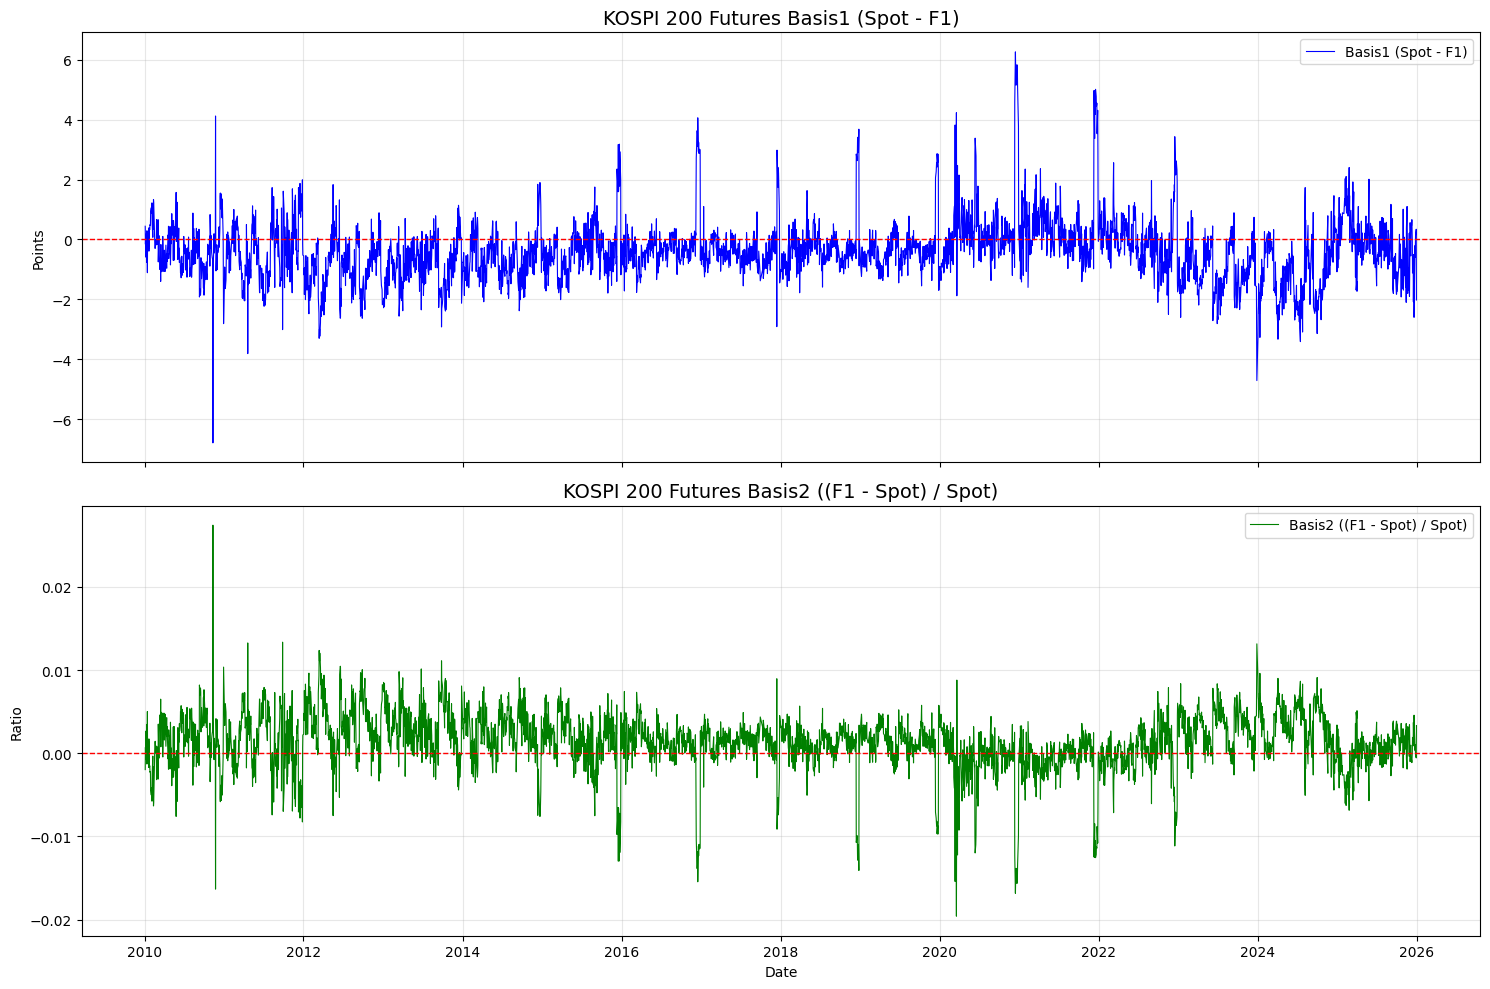

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import files

# 1. 날짜 데이터 형식 변환
basis_df['Date'] = pd.to_datetime(basis_df['Date'])

# 2. 그래프 설정
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

# Basis 1 그래프 (S - F)
ax1.plot(basis_df['Date'], basis_df['Basis1'], color='blue', linewidth=0.8, label='Basis1 (Spot - F1)')
ax1.axhline(0, color='red', linestyle='--', linewidth=1)
ax1.set_title('KOSPI 200 Futures Basis1 (Spot - F1)', fontsize=14)
ax1.set_ylabel('Points')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Basis 2 그래프 ((F - S) / S)
ax2.plot(basis_df['Date'], basis_df['Basis2'], color='green', linewidth=0.8, label='Basis2 ((F1 - Spot) / Spot)')
ax2.axhline(0, color='red', linestyle='--', linewidth=1)
ax2.set_title('KOSPI 200 Futures Basis2 ((F1 - Spot) / Spot)', fontsize=14)
ax2.set_ylabel('Ratio')
ax2.set_xlabel('Date')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()

# 3. 이미지 파일로 저장 및 다운로드
plot_filename = 'kospi200_basis_plot.png'
plt.savefig(plot_filename, dpi=300)
plt.show()

files.download(plot_filename)

# Step 6: Basis dataset 평균, 표준편차, 최소값, 최대값 계산

In [11]:
# Basis dataset의 주요 통계량 계산
stats_df = basis_df[['Basis1', 'Basis2']].describe().loc[['mean', 'std', 'min', 'max']]

# 결과 출력
print("[Basis Dataset Statistics: 2010 - 2025]")
display(stats_df)

# 개별 출력 (보기 편하게)
for col in ['Basis1', 'Basis2']:
    print(f"\n--- {col} Statistics ---")
    print(f"평균 (Mean): {basis_df[col].mean():.6f}")
    print(f"표준편차 (Std): {basis_df[col].std():.6f}")
    print(f"최소값 (Min): {basis_df[col].min():.6f}")
    print(f"최대값 (Max): {basis_df[col].max():.6f}")

[Basis Dataset Statistics: 2010 - 2025]


,Basis1,Basis2
mean,-0.384895,0.001363
std,1.009470,0.003412
min,-6.790000,-0.019599
max,6.260000,0.027433



--- Basis1 Statistics ---
평균 (Mean): -0.384895
표준편차 (Std): 1.009470
최소값 (Min): -6.790000
최대값 (Max): 6.260000

--- Basis2 Statistics ---
평균 (Mean): 0.001363
표준편차 (Std): 0.003412
최소값 (Min): -0.019599
최대값 (Max): 0.027433


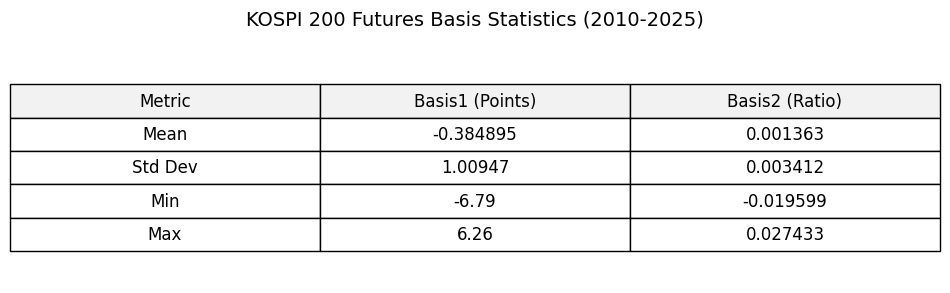

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import files

# 1. 정리된 통계 데이터 (한글 깨짐 방지를 위해 영문 라벨 사용)
stats_data = {
    'Metric': ['Mean', 'Std Dev', 'Min', 'Max'],
    'Basis1 (Points)': [basis_df['Basis1'].mean(), basis_df['Basis1'].std(), basis_df['Basis1'].min(), basis_df['Basis1'].max()],
    'Basis2 (Ratio)': [basis_df['Basis2'].mean(), basis_df['Basis2'].std(), basis_df['Basis2'].min(), basis_df['Basis2'].max()]
}
summary_table = pd.DataFrame(stats_data)

# 2. 시각화 설정
fig, ax = plt.subplots(figsize=(10, 3))
ax.axis('off')

# 표 생성
the_table = ax.table(cellText=summary_table.round(6).values,
                      colLabels=summary_table.columns,
                      cellLoc='center',
                      loc='center',
                      colColours=['#f2f2f2']*3)

the_table.auto_set_font_size(False)
the_table.set_fontsize(12)
the_table.scale(1.2, 2)

plt.title('KOSPI 200 Futures Basis Statistics (2010-2025)', fontsize=14, pad=20)

# 3. 파일 저장 및 다운로드
stats_plot_name = 'basis_statistics.png'
plt.savefig(stats_plot_name, dpi=300, bbox_inches='tight')
plt.show()

files.download(stats_plot_name)

# Step 7: 만기수렴 분석

[Convergence Analysis: Basis by Days to Maturity]


,Days to Maturity,Avg |Basis1| (Points),Avg |Basis2| (Ratio)
0,D-30,0.540172,0.001902
1,D-10,0.438621,0.001548
2,D-5,0.220000,0.000829
3,D-1,0.313333,0.001112


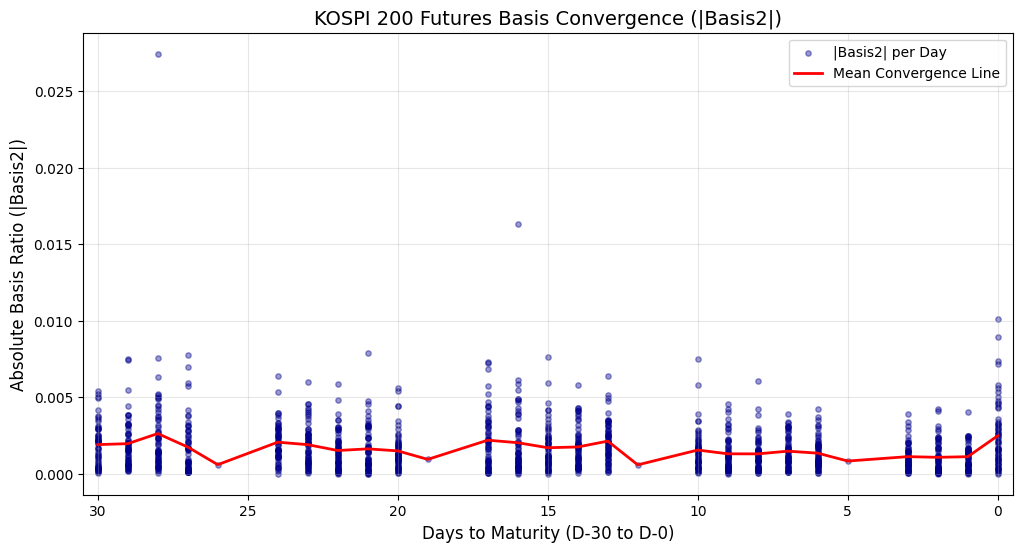

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. 데이터 로드
df_conv = pd.read_csv('/content/kospi200_2010_2025_refined.csv')

# 2. 데이터 전처리
# '만기까지 남은 일수' 계산 (TTM1은 연 단위)
df_conv['Days_to_Maturity'] = (df_conv['TTM1'] * 365).round(0).astype(int)

# 베이시스 재계산 (파일에 없는 경우 대비)
df_conv['Basis1'] = df_conv['Spot'] - df_conv['F1_Price']
df_conv['Basis2'] = (df_conv['F1_Price'] - df_conv['Spot']) / df_conv['Spot']

# 절대 베이시스 계산
df_conv['Abs_Basis1'] = df_conv['Basis1'].abs()
df_conv['Abs_Basis2'] = df_conv['Basis2'].abs()

# 3. 구간별 비교 (Table)
target_days = [30, 10, 5, 1]
summary_list = []

for d in target_days:
    subset = df_conv[df_conv['Days_to_Maturity'] == d]
    summary_list.append({
        'Days to Maturity': f'D-{d}',
        'Avg |Basis1| (Points)': subset['Abs_Basis1'].mean(),
        'Avg |Basis2| (Ratio)': subset['Abs_Basis2'].mean()
    })

convergence_table = pd.DataFrame(summary_list)
print("[Convergence Analysis: Basis by Days to Maturity]")
display(convergence_table)

# 4. 시각화 (Scatter Plot)
plt.figure(figsize=(12, 6))

# 만기 30일 이내 데이터만 필터링
plot_data = df_conv[(df_conv['Days_to_Maturity'] <= 30) & (df_conv['Days_to_Maturity'] >= 0)]

plt.scatter(plot_data['Days_to_Maturity'], plot_data['Abs_Basis2'],
            alpha=0.4, s=15, color='darkblue', label='|Basis2| per Day')

# 추세 확인을 위한 평균선
avg_by_day = plot_data.groupby('Days_to_Maturity')['Abs_Basis2'].mean()
plt.plot(avg_by_day.index, avg_by_day.values, color='red', linewidth=2, label='Mean Convergence Line')

# X축 역순 설정 (30 -> 0)
plt.xlim(30.5, -0.5)
plt.title('KOSPI 200 Futures Basis Convergence (|Basis2|)', fontsize=14)
plt.xlabel('Days to Maturity (D-30 to D-0)', fontsize=12)
plt.ylabel('Absolute Basis Ratio (|Basis2|)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend()

# 5. 결과 저장 및 다운로드
conv_plot_name = 'basis_convergence_plot.png'
plt.savefig(conv_plot_name, dpi=300, bbox_inches='tight')
plt.show()

convergence_table.to_csv('kospi200_convergence_summary.csv', index=False, encoding='utf-8-sig')
files.download(conv_plot_name)
files.download('kospi200_convergence_summary.csv')

작업결과


---

1. 데이터 전처리: TTM1을 기반으로 '만기까지 남은 일수(Days to Maturity)'를 계산하고, 베이시스의 절대값($|Basis_1|, |Basis_2|$$|Basis_1|, |Basis_2|$) 컬럼을 추가
2. 구간별 비교: 만기 30일, 10일, 5일, 1일 전 시점의 절대 베이시스 평균을 산출하여 표로 정리
3. 시각화: 만기일이 다가올수록($30 \to 0$$30 \to 0$) 절대 괴리율($|Basis_2|$$|Basis_2|$)이 어떻게 0으로 수렴하는지 산점도를 통해 확인.

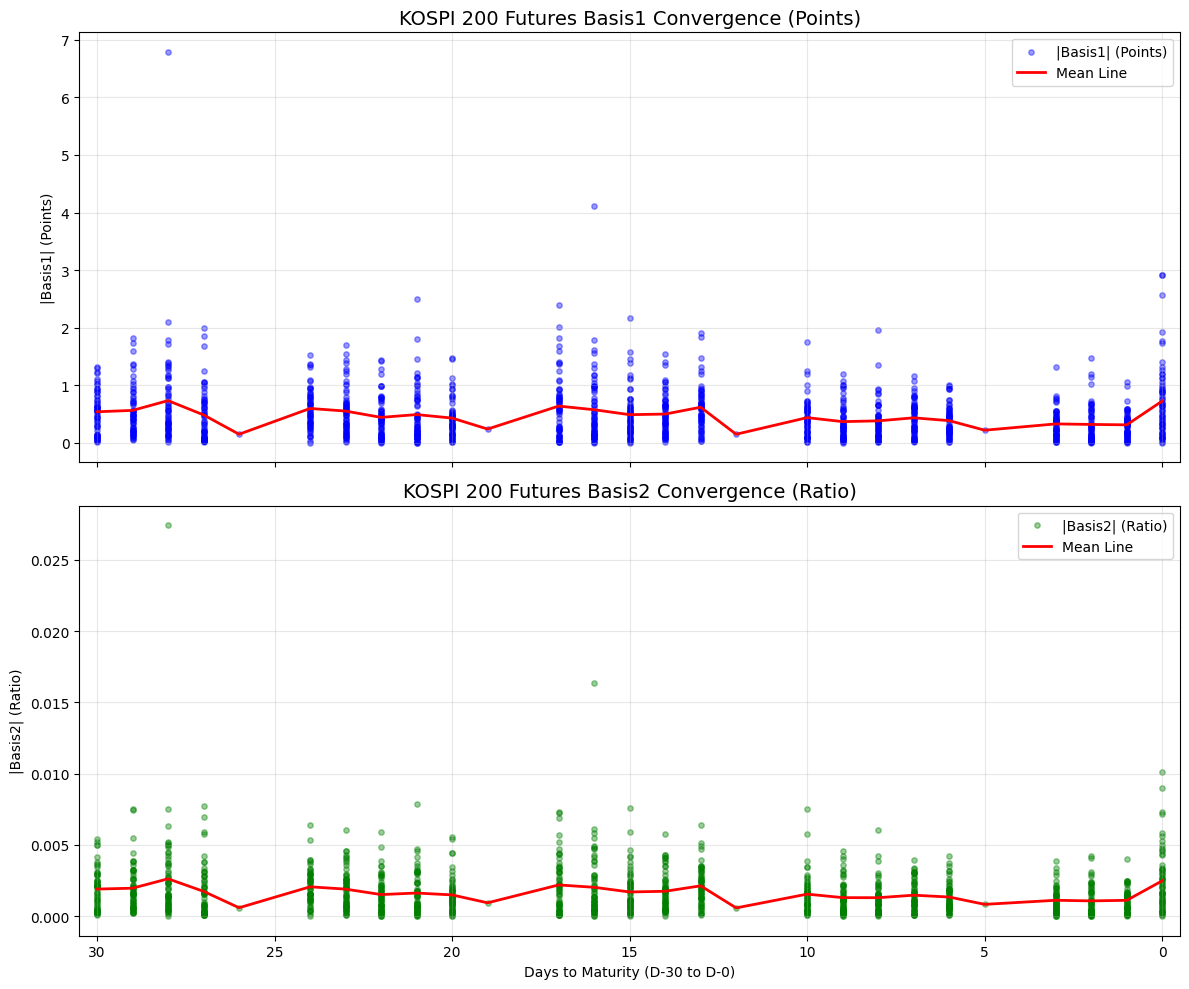

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
import matplotlib.pyplot as plt
from google.colab import files

# 2개의 서브플롯 생성 (Basis1과 Basis2 비교)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

# 만기 30일 이내 데이터 필터링
plot_data = df_conv[(df_conv['Days_to_Maturity'] <= 30) & (df_conv['Days_to_Maturity'] >= 0)]

# 1. Basis1 (Points) 수렴 현상
ax1.scatter(plot_data['Days_to_Maturity'], plot_data['Abs_Basis1'], alpha=0.4, s=15, color='blue', label='|Basis1| (Points)')
avg_b1 = plot_data.groupby('Days_to_Maturity')['Abs_Basis1'].mean()
ax1.plot(avg_b1.index, avg_b1.values, color='red', linewidth=2, label='Mean Line')
ax1.set_title('KOSPI 200 Futures Basis1 Convergence (Points)', fontsize=14)
ax1.set_ylabel('|Basis1| (Points)')
ax1.grid(True, alpha=0.3)
ax1.legend()

# 2. Basis2 (Ratio) 수렴 현상
ax2.scatter(plot_data['Days_to_Maturity'], plot_data['Abs_Basis2'], alpha=0.4, s=15, color='green', label='|Basis2| (Ratio)')
avg_b2 = plot_data.groupby('Days_to_Maturity')['Abs_Basis2'].mean()
ax2.plot(avg_b2.index, avg_b2.values, color='red', linewidth=2, label='Mean Line')
ax2.set_title('KOSPI 200 Futures Basis2 Convergence (Ratio)', fontsize=14)
ax2.set_ylabel('|Basis2| (Ratio)')
ax2.set_xlabel('Days to Maturity (D-30 to D-0)')
ax2.grid(True, alpha=0.3)
ax2.legend()

# X축 역순 설정
plt.xlim(30.5, -0.5)
plt.tight_layout()

# 이미지 파일로 저장 및 다운로드
conv_refined_plot_name = 'kospi200_convergence_refined_plot.png'
plt.savefig(conv_refined_plot_name, dpi=300, bbox_inches='tight')
plt.show()

files.download(conv_refined_plot_name)

Basis 1, 2 의 수렴 현상 산점표로 시각화

# Step 8: Forward Curve

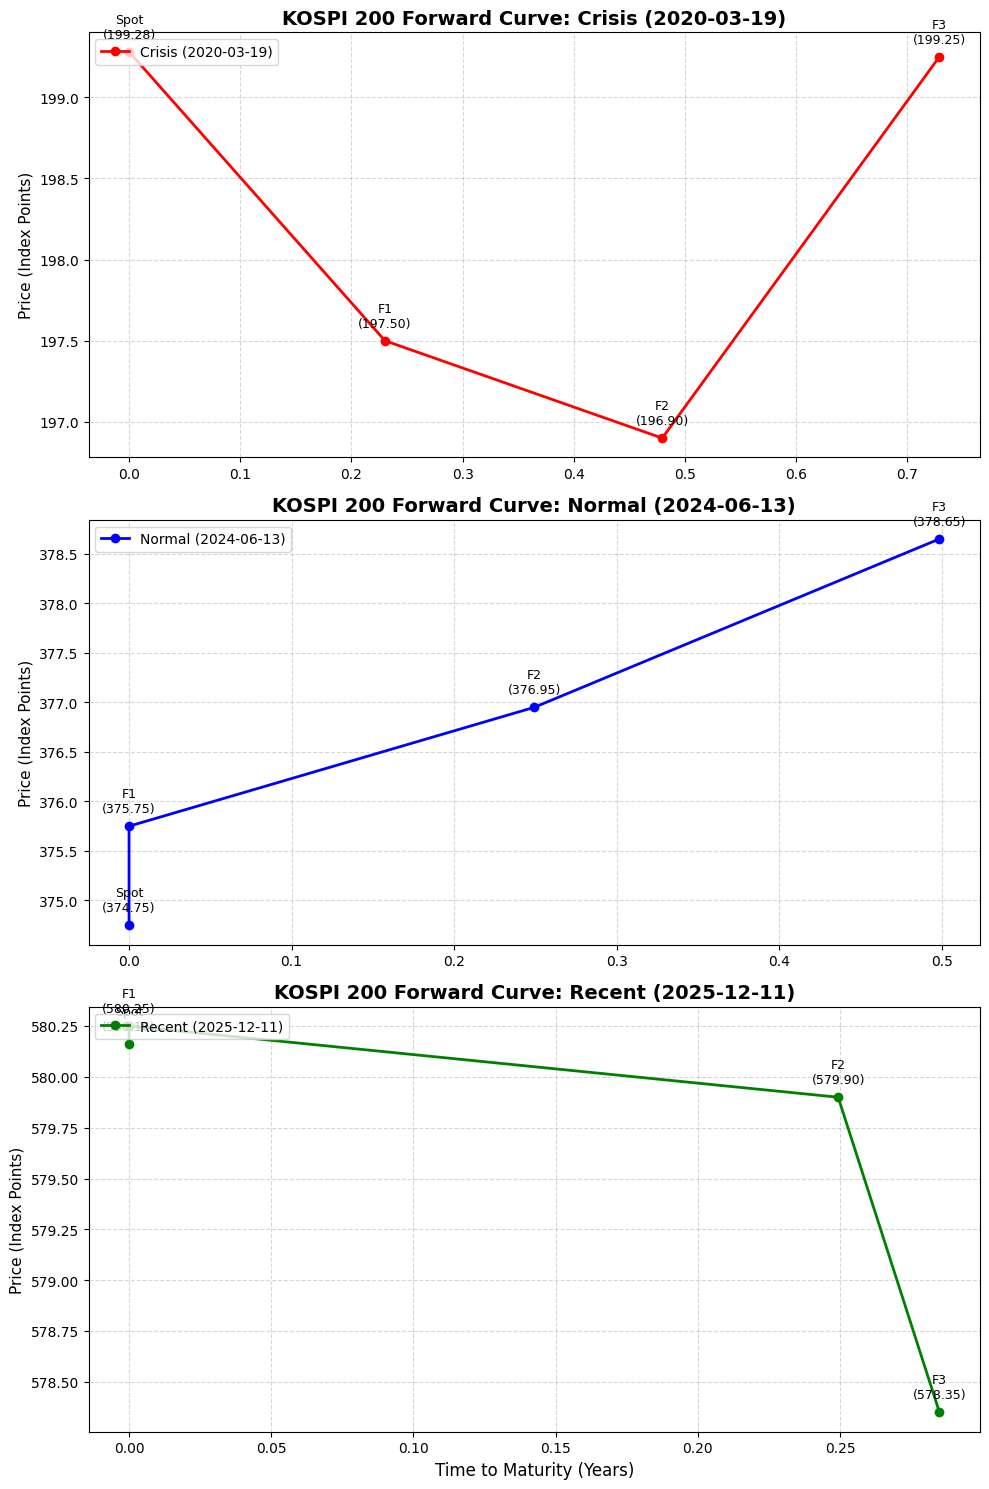

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# 1. Load the refined dataset
df_refined = pd.read_csv('/content/kospi200_2010_2025_refined.csv')

# 2. Select representative dates
# Crisis: COVID-19 (2020-03-19), Normal: 2024-06-13, Recent: 2025-12-11
target_dates = ['2020-03-19', '2024-06-13', '2025-12-11']
labels = ['Crisis (2020-03-19)', 'Normal (2024-06-13)', 'Recent (2025-12-11)']
colors = ['red', 'blue', 'green']

# 3. Create 3 subplots for better visualization
fig, axes = plt.subplots(3, 1, figsize=(10, 15))

for i, (date, label, color) in enumerate(zip(target_dates, labels, colors)):
    ax = axes[i]
    # Extract data for the specific date
    row = df_refined[df_refined['Date'] == date]

    if not row.empty:
        row = row.iloc[0]
        # X-axis: TTM (Spot is at 0)
        ttms = [0, row['TTM1'], row['TTM2'], row['TTM3']]
        # Y-axis: Prices
        prices = [row['Spot'], row['F1_Price'], row['F2_Price'], row['F3_Price']]

        # Plot the curve
        ax.plot(ttms, prices, marker='o', linestyle='-', color=color, label=label, linewidth=2)

        # Annotate each point with Price and label
        points_labels = ['Spot', 'F1', 'F2', 'F3']
        for j, txt in enumerate(points_labels):
            ax.annotate(f"{txt}\n({prices[j]:.2f})", (ttms[j], prices[j]),
                         textcoords="offset points", xytext=(0,10), ha='center', fontsize=9)

        ax.set_title(f'KOSPI 200 Forward Curve: {label}', fontsize=14, fontweight='bold')
        ax.set_ylabel('Price (Index Points)', fontsize=11)
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.legend(loc='upper left')

# Shared X-label
axes[2].set_xlabel('Time to Maturity (Years)', fontsize=12)
plt.tight_layout()

# 4. Save and Download the high-resolution image
forward_plot_name = 'kospi200_forward_curve_analysis.png'
plt.savefig(forward_plot_name, dpi=300, bbox_inches='tight')
plt.show()

files.download(forward_plot_name)

# Step 9: Contango와 Backwardation 분류

--- Overall Term Structure Statistics (2010-2025) ---
Mixed/Other: 58.47% (2303 days)
Contango: 31.2% (1229 days)
Backwardation: 10.31% (406 days)
Undefined: 0.03% (1 days)


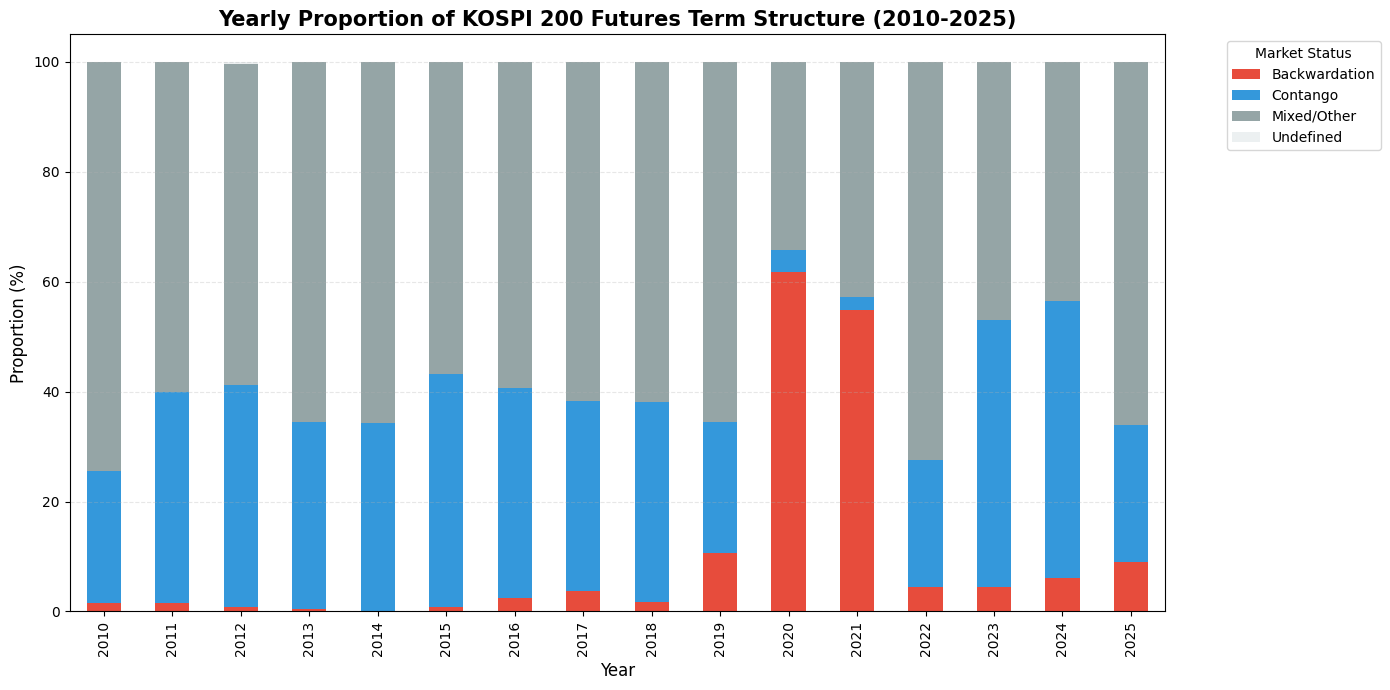

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files

# 1. Load refined dataset
df = pd.read_csv('/content/kospi200_2010_2025_refined.csv')
df['Date'] = pd.to_datetime(df['Date'])
df['Year'] = df['Date'].dt.year

# 2. Define classification function
def classify_status(row):
    f1, f2, f3 = row['F1_Price'], row['F2_Price'], row['F3_Price']
    if pd.isna(f1) or pd.isna(f2) or pd.isna(f3):
        return 'Undefined'
    if f1 < f2 < f3:
        return 'Contango'
    elif f1 > f2 > f3:
        return 'Backwardation'
    else:
        return 'Mixed/Other'

# Apply classification
df['Status'] = df.apply(classify_status, axis=1)

# 3. Overall Statistics
total_days = len(df)
stats = df['Status'].value_counts()
proportions = (stats / total_days * 100).round(2)

print("--- Overall Term Structure Statistics (2010-2025) ---")
for status, proc in proportions.items():
    print(f"{status}: {proc}% ({stats[status]} days)")

# 4. Yearly Proportion Calculation for Stacked Bar Chart
yearly_stats = df.groupby(['Year', 'Status']).size().unstack(fill_value=0)
yearly_pct = yearly_stats.div(yearly_stats.sum(axis=1), axis=0) * 100

# 5. Visualization
fig, ax = plt.subplots(figsize=(14, 7))

# Define colors for the status
color_map = {'Contango': '#3498db', 'Backwardation': '#e74c3c', 'Mixed/Other': '#95a5a6', 'Undefined': '#ecf0f1'}

yearly_pct.plot(kind='bar', stacked=True, ax=ax, color=[color_map.get(x, '#333') for x in yearly_pct.columns])

ax.set_title('Yearly Proportion of KOSPI 200 Futures Term Structure (2010-2025)', fontsize=15, fontweight='bold')
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Proportion (%)', fontsize=12)
ax.legend(title='Market Status', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plot_name = 'term_structure_yearly_distribution.png'
plt.savefig(plot_name, dpi=300)
plt.show()

# Save classified data
df.to_csv('kospi200_classified_status.csv', index=False, encoding='utf-8-sig')
files.download(plot_name)
files.download('kospi200_classified_status.csv')

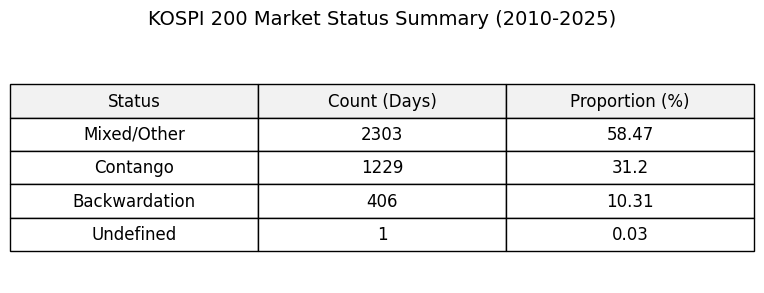

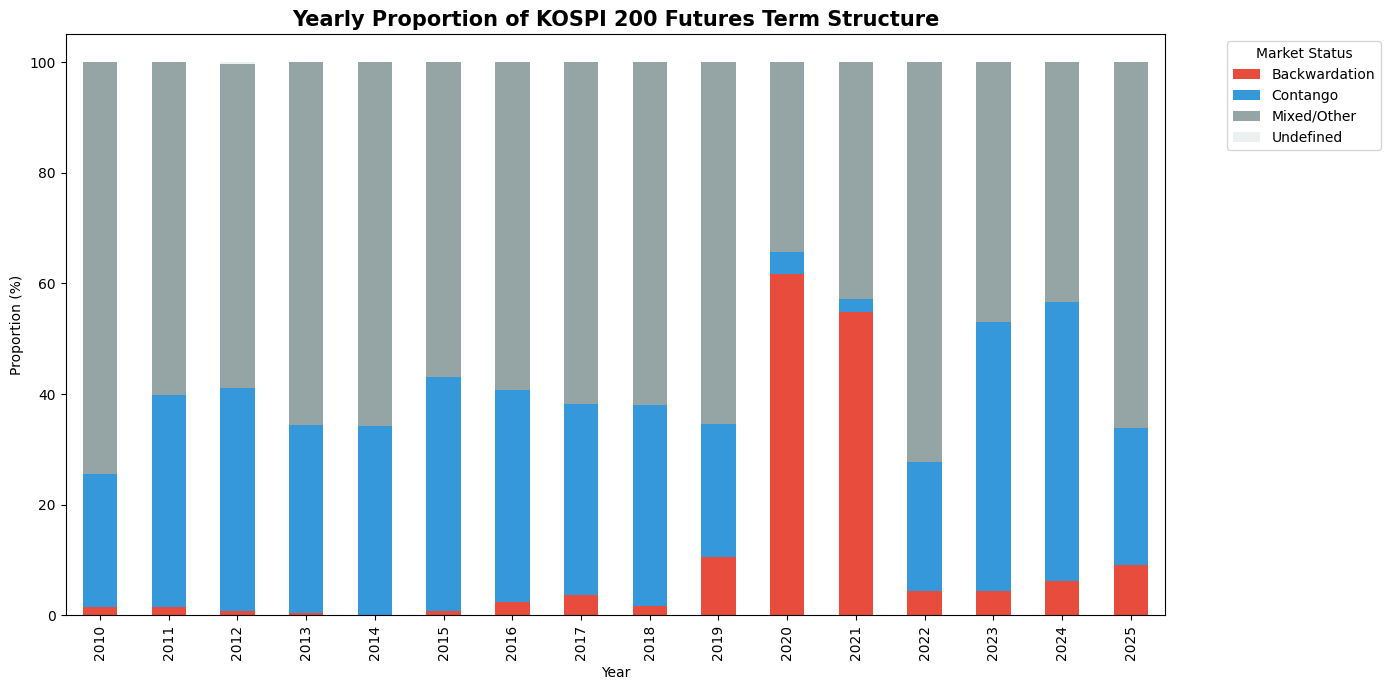

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import files

# 1. Load the classified data
df_status = pd.read_csv('kospi200_classified_status.csv')

# 2. Create Summary Statistics Table Image
stats = df_status['Status'].value_counts()
proportions = (stats / len(df_status) * 100).round(2)
summary_df = pd.DataFrame({
    'Status': stats.index,
    'Count (Days)': stats.values,
    'Proportion (%)': proportions.values
})

fig_table, ax_table = plt.subplots(figsize=(8, 3))
ax_table.axis('off')
table = ax_table.table(cellText=summary_df.values,
                      colLabels=summary_df.columns,
                      cellLoc='center',
                      loc='center',
                      colColours=['#f2f2f2']*3)
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.2, 2)
plt.title('KOSPI 200 Market Status Summary (2010-2025)', fontsize=14, pad=20)

stats_img_name = 'market_status_statistics.png'
plt.savefig(stats_img_name, dpi=300, bbox_inches='tight')
plt.show()

# 3. Create Yearly Distribution Chart Image (Re-rendering for safety)
df_status['Date'] = pd.to_datetime(df_status['Date'])
df_status['Year'] = df_status['Date'].dt.year
yearly_pct = df_status.groupby(['Year', 'Status']).size().unstack(fill_value=0)
yearly_pct = yearly_pct.div(yearly_pct.sum(axis=1), axis=0) * 100

fig_bar, ax_bar = plt.subplots(figsize=(14, 7))
color_map = {'Contango': '#3498db', 'Backwardation': '#e74c3c', 'Mixed/Other': '#95a5a6', 'Undefined': '#ecf0f1'}
yearly_pct.plot(kind='bar', stacked=True, ax=ax_bar, color=[color_map.get(x, '#333') for x in yearly_pct.columns])

ax_bar.set_title('Yearly Proportion of KOSPI 200 Futures Term Structure', fontsize=15, fontweight='bold')
ax_bar.set_ylabel('Proportion (%)')
ax_bar.legend(title='Market Status', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

bar_img_name = 'market_status_yearly_chart.png'
plt.savefig(bar_img_name, dpi=300)
plt.show()

# 4. Download files
files.download(stats_img_name)
files.download(bar_img_name)

Step 10: forward curve의 기울기를 수치화 &  평균, 분산 구하기

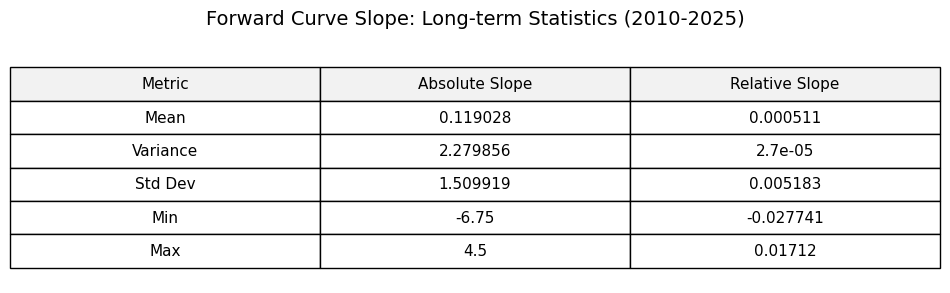

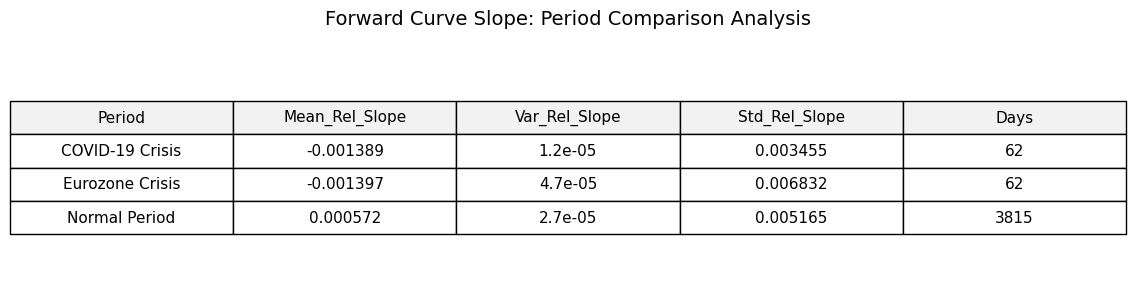

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import files

# 1. 시각화를 위한 테이블 데이터 준비 (이전 셀의 결과물 활용)
# overall_stats 와 period_comparison 변수가 메모리에 있어야 합니다.

# 2. 장기 기초 통계량 (Long-term Stats) PNG 저장
fig_stats, ax_stats = plt.subplots(figsize=(10, 3))
ax_stats.axis('off')
table_stats = ax_stats.table(cellText=overall_stats.round(6).values,
                            colLabels=overall_stats.columns,
                            cellLoc='center',
                            loc='center',
                            colColours=['#f2f2f2']*3)
table_stats.auto_set_font_size(False)
table_stats.set_fontsize(11)
table_stats.scale(1.2, 2)
plt.title('Forward Curve Slope: Long-term Statistics (2010-2025)', fontsize=14, pad=20)

stats_img_name = 'slope_overall_statistics.png'
plt.savefig(stats_img_name, dpi=300, bbox_inches='tight')
plt.show()

# 3. 국면별 비교 분석 (Period Comparison) PNG 저장
fig_period, ax_period = plt.subplots(figsize=(12, 3))
ax_period.axis('off')
table_period = ax_period.table(cellText=period_comparison.round(6).values,
                              colLabels=period_comparison.columns,
                              cellLoc='center',
                              loc='center',
                              colColours=['#f2f2f2']*5)
table_period.auto_set_font_size(False)
table_period.set_fontsize(11)
table_period.scale(1.2, 2)
plt.title('Forward Curve Slope: Period Comparison Analysis', fontsize=14, pad=20)

period_img_name = 'slope_period_comparison.png'
plt.savefig(period_img_name, dpi=300, bbox_inches='tight')
plt.show()

# 4. 파일 다운로드
files.download(stats_img_name)
files.download(period_img_name)

--- Long-term Forward Curve Slope Statistics (2010-2025) ---


,Metric,Absolute Slope,Relative Slope
0,Mean,0.119028,0.000511
1,Variance,2.279856,0.000027
2,Std Dev,1.509919,0.005183
3,Min,-6.750000,-0.027741
4,Max,4.500000,0.017120



--- Period Comparison: Slope Analysis ---


,Period,Mean_Rel_Slope,Var_Rel_Slope,Std_Rel_Slope,Days
0,COVID-19 Crisis,-0.001389,0.000012,0.003455,62
1,Eurozone Crisis,-0.001397,0.000047,0.006832,62
2,Normal Period,0.000572,0.000027,0.005165,3815


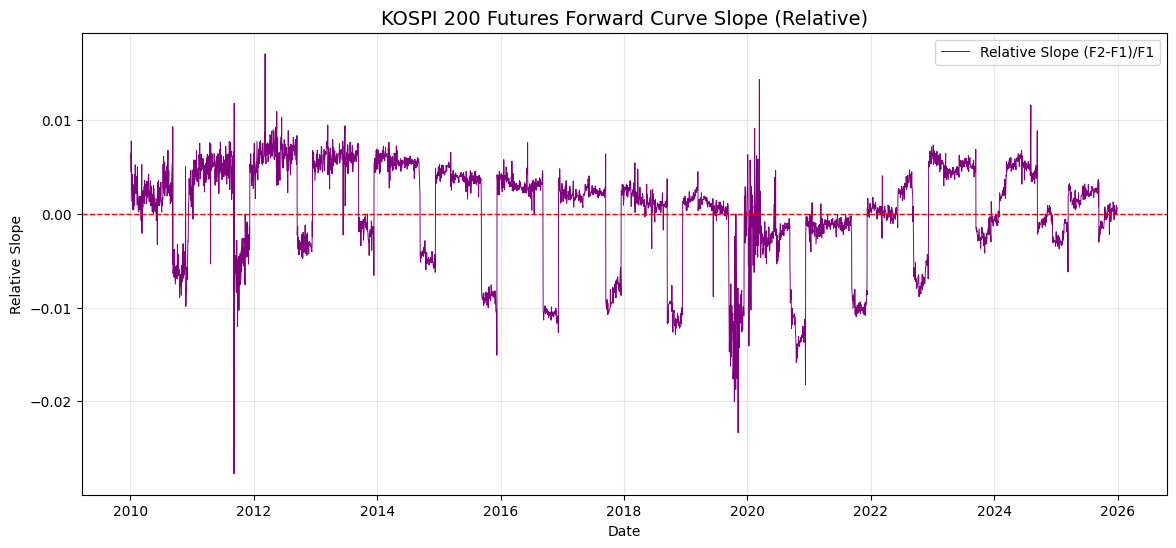

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. Load the refined dataset
df_slope = pd.read_csv('/content/kospi200_2010_2025_refined.csv')
df_slope['Date'] = pd.to_datetime(df_slope['Date'])

# 2. (a) Calculate Slopes
# Absolute Slope: F2 - F1
df_slope['Slope_Abs'] = df_slope['F2_Price'] - df_slope['F1_Price']

# Relative Slope: (F2 - F1) / F1
df_slope['Slope_Rel'] = (df_slope['F2_Price'] - df_slope['F1_Price']) / df_slope['F1_Price']

# 3. (b) Long-term Statistics (2010-2025)
overall_stats = pd.DataFrame({
    'Metric': ['Mean', 'Variance', 'Std Dev', 'Min', 'Max'],
    'Absolute Slope': [
        df_slope['Slope_Abs'].mean(),
        df_slope['Slope_Abs'].var(),
        df_slope['Slope_Abs'].std(),
        df_slope['Slope_Abs'].min(),
        df_slope['Slope_Abs'].max()
    ],
    'Relative Slope': [
        df_slope['Slope_Rel'].mean(),
        df_slope['Slope_Rel'].var(),
        df_slope['Slope_Rel'].std(),
        df_slope['Slope_Rel'].min(),
        df_slope['Slope_Rel'].max()
    ]
})

print("--- Long-term Forward Curve Slope Statistics (2010-2025) ---")
display(overall_stats)

# 4. (c) Crisis vs. Normal Period Analysis
def classify_period(date):
    # COVID-19 Crisis: 2020-02-01 to 2020-04-30
    if pd.Timestamp('2020-02-01') <= date <= pd.Timestamp('2020-04-30'):
        return 'COVID-19 Crisis'
    # Eurozone Crisis: 2011-08-01 to 2011-10-31
    elif pd.Timestamp('2011-08-01') <= date <= pd.Timestamp('2011-10-31'):
        return 'Eurozone Crisis'
    else:
        return 'Normal Period'

df_slope['Period'] = df_slope['Date'].apply(classify_period)

period_comparison = df_slope.groupby('Period').agg({
    'Slope_Rel': ['mean', 'var', 'std', 'count']
}).reset_index()

period_comparison.columns = ['Period', 'Mean_Rel_Slope', 'Var_Rel_Slope', 'Std_Rel_Slope', 'Days']

print("\n--- Period Comparison: Slope Analysis ---")
display(period_comparison)

# 5. Visualization: Slope Time Series
plt.figure(figsize=(14, 6))
plt.plot(df_slope['Date'], df_slope['Slope_Rel'], color='purple', linewidth=0.7, label='Relative Slope (F2-F1)/F1')
plt.axhline(0, color='red', linestyle='--', linewidth=1)
plt.title('KOSPI 200 Futures Forward Curve Slope (Relative)', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Relative Slope')
plt.grid(True, alpha=0.3)
plt.legend()

slope_plot_name = 'kospi200_slope_timeseries.png'
plt.savefig(slope_plot_name, dpi=300)
plt.show()

# 6. Save and Download
df_slope.to_csv('kospi200_slope_analysis.csv', index=False, encoding='utf-8-sig')
files.download('kospi200_slope_analysis.csv')
files.download(slope_plot_name)

# Step 11: 위기구간 비교분석

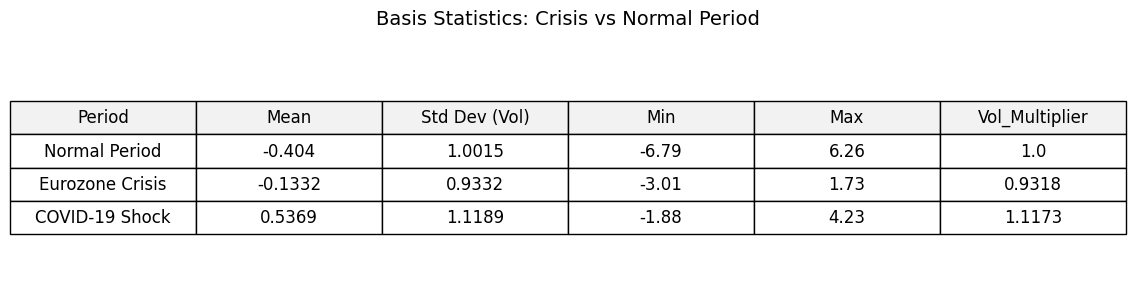

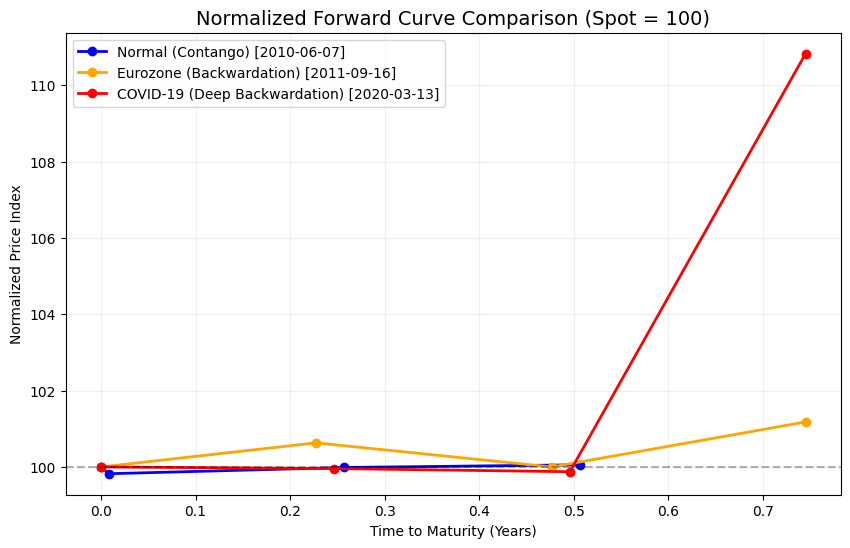

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. 데이터 로드 및 베이시스 재계산
df_event = pd.read_csv('/content/kospi200_2010_2025_refined.csv')
df_event['Date'] = pd.to_datetime(df_event['Date'])
df_event['Basis1'] = df_event['Spot'] - df_event['F1_Price']

# 2. 분석 구간(Period) 설정
euro_start = df_event[df_event['Date'] >= '2011-08-01'].index[0]
euro_period = df_event.iloc[euro_start : euro_start + 62].copy()
covid_start = df_event[df_event['Date'] >= '2020-02-17'].index[0]
covid_period = df_event.iloc[covid_start : covid_start + 62].copy()
normal_period = df_event.drop(list(euro_period.index) + list(covid_period.index)).copy()

# 3. 베이시스 통계 비교
stats_list = []
for p, name in zip([normal_period, euro_period, covid_period], ['Normal Period', 'Eurozone Crisis', 'COVID-19 Shock']):
    b_stats = p['Basis1'].describe()
    stats_list.append({
        'Period': name,
        'Mean': b_stats['mean'],
        'Std Dev (Vol)': b_stats['std'],
        'Min': b_stats['min'],
        'Max': b_stats['max']
    })

event_stats_df = pd.DataFrame(stats_list)
normal_vol = event_stats_df.loc[event_stats_df['Period'] == 'Normal Period', 'Std Dev (Vol)'].values[0]
event_stats_df['Vol_Multiplier'] = event_stats_df['Std Dev (Vol)'] / normal_vol
event_stats_df = event_stats_df.round(4)

# 4. 통계 테이블 PNG 저장
fig_table, ax_table = plt.subplots(figsize=(12, 3))
ax_table.axis('off')
the_table = ax_table.table(cellText=event_stats_df.values, colLabels=event_stats_df.columns, cellLoc='center', loc='center', colColours=['#f2f2f2']*6)
the_table.auto_set_font_size(False)
the_table.set_fontsize(12)
the_table.scale(1.2, 2)
plt.title('Basis Statistics: Crisis vs Normal Period', fontsize=14, pad=20)
stats_png = 'market_event_statistics.png'
plt.savefig(stats_png, dpi=300, bbox_inches='tight')
plt.show()

# 5. 대표 Forward Curve 시각화 및 PNG 저장
rep_normal = normal_period[normal_period['F2_Price'] > normal_period['F1_Price']].iloc[100]
rep_euro = euro_period[euro_period['F1_Price'] > euro_period['F2_Price']].iloc[5]
rep_covid = covid_period[covid_period['F1_Price'] > covid_period['F2_Price']].iloc[10]

plt.figure(figsize=(10, 6))
for day, label, color in zip([rep_normal, rep_euro, rep_covid],
                             ['Normal (Contango)', 'Eurozone (Backwardation)', 'COVID-19 (Deep Backwardation)'],
                             ['blue', 'orange', 'red']):
    ttms = [0, day['TTM1'], day['TTM2'], day['TTM3']]
    prices = [day['Spot'], day['F1_Price'], day['F2_Price'], day['F3_Price']]
    norm_prices = [p / day['Spot'] * 100 for p in prices]
    plt.plot(ttms, norm_prices, marker='o', label=f"{label} [{day['Date'].strftime('%Y-%m-%d')}]", color=color, linewidth=2)

plt.axhline(100, color='black', linestyle='--', alpha=0.3)
plt.title('Normalized Forward Curve Comparison (Spot = 100)', fontsize=14)
plt.xlabel('Time to Maturity (Years)')
plt.ylabel('Normalized Price Index')
plt.legend()
plt.grid(True, alpha=0.2)
curve_png = 'event_analysis_forward_curve.png'
plt.savefig(curve_png, dpi=300)
plt.show()

# 6. 모든 결과물 다운로드
event_stats_df.to_csv('market_event_comparison.csv', index=False, encoding='utf-8-sig')
files.download('market_event_comparison.csv')
files.download(stats_png)
files.download(curve_png)